# Do the neurons that carry a fine-tune have an old job that names the task? (E101, 67M)

## The answer

No, not on this model. For each neuron that carries a fine-tune's gain, we wrote its job from the Pile and asked a
judge whether the job relates to the task. Almost none did, whether the task was built to reuse or to be new. Shown
each task's own examples, the judge still tied none of the original model's task-specific neurons to their task. So
this reading cannot tell reuse from new on the 67M, and the next step is the larger Qwen model.

*Provisional: fast lane, no independent check. Covers the run and its Amendment 1. Full record:
`reports/analyses/2026-11-05_analysis_e101-carrying-jobs.md`.*


## What we were trying to test

`GOALS.md` asks whether post-training reuses what a model already does or adds something new. The previous experiment,
E98, found for each of 43 saved fine-tunes of the 67M which MLP neurons of the original model carry the gain when they
fire differently with their weights unchanged. Call those neurons the fine-tune's **carrying set**. This experiment asks
what job those neurons had before training. If a fine-tune built to reuse an ability is carried by neurons whose old job
already relates to the task, and one built to be new is not, then a neuron's job reads reuse without any decomposition.
The labels "built to reuse" and "built to be new" describe how each task was made; they are assumptions, except copy
against lookup, which a check on the original model's copying head labelled.

We read each neuron the way the "already clean" essay reads neurons, in four steps, each by a separate agent that sees
only what the step needs:

1. **Pile windows.** Each neuron's 20 strongest windows from 2,000 Pile rows, with the peak token marked.
2. **Writer.** From those windows alone, a one-line job.
3. **Maximiser.** From the job alone, five texts that should fire the neuron and five near misses that should not. The
   model scores each text. A text fires **strongly** at 30% of the neuron's strongest Pile window or more, the essay's
   bar. The job **wins** when more examples than near misses fire strongly.
4. **Judge.** From the jobs and six one-line task descriptions, which tasks each job would plausibly help.

The **related share** of a set of neurons is the share whose job wins and is tied to the set's own task: 0 means no
neuron's job names the task, 1 means every one does.

Three kinds of neuron were mixed in the same batches. The **carrying** neurons come from eight groups of fine-tunes,
16 to 24 each. Each group has a **random partner** of the same size, matched by layer, which gives the floor: how often
an unrelated job is tied to a task. The **W₀ top firers** are the positive control: on three tasks, the ten neurons
outside every carrying set that fire hardest at the answer position in the original model. If the method can tie
anything to a task, it should tie these.

**Amendment 1** fixed two faults the first run exposed, and re-judged every neuron with no new GPU work. The new judge
sees each task's description with four of its own windows, the answer token marked, and excludes no kind of token. The
new control is a set of **task-specific picks**: on lowercase, the same-word map and lookup, the ten neurons whose firing
at the answer most exceeds their firing on the other tasks. If the judge does not tie these to their own task more often
than random neurons, the plan closes this route on the 67M.


## What we expected, and why

- **The judge would tie lowercase's carrying neurons to lowercase text.** Lowercase is the easiest case: ordinary
  English, which a model trained on web text has neurons for. We filed that its related share would beat the random
  floor by at least 0.2. If this failed, the method had no power, and the comparisons below would be reported but not
  read.
- **Built-to-reuse fine-tunes would read more related than built-to-be-new ones** on at least two of three pairs:
  lowercase against ciphers, same-word maps against random-word maps, copy against lookup.
- **The rank-1 maps' carrying neurons might be one coherent job.** Their update has rank one, so their carrying neurons
  could share a job, or be an artefact of the rank. No lean.
- **Before any agent ran,** lowercase's carrying neurons would already fire more at the answer position than the
  ciphers'. That measure is a quantile of each neuron's own Pile firing: 0.5 is a typical position, 1 its strongest.
- **Amendment 1: shown the task, the judge would tie each task's specific picks to that task,** by the same 0.2 over the
  random floor, about three or four of ten. We leaned pass on the same-word map and lookup, whose marker-and-key format
  is easy to name, and left lowercase open, since its picks fired only a little more on it than on other tasks.


In [1]:
import json
from pathlib import Path

from IPython.display import Image, display

from commute.jobs import load_experiment

PLOT = load_experiment("carrying_jobs", "plot")
PLOT.main()  # redraws the four figures from the agent outputs and the keys
FIG = Path("../experiments/carrying_jobs/figures")
RES = Path("../experiments/carrying_jobs/results")
score = json.loads((RES / "score.json").read_text())
amend1 = json.loads((RES / "score_amend1.json").read_text())
print(f"filed run: neurons with every output {score['complete']} of {score['n_neurons']}")
print(f"Amendment 1: neurons judged {amend1['judged']} of {amend1['n_neurons']}")


figures in experiments/carrying_jobs/figures
filed run: neurons with every output 351 of 352
Amendment 1: neurons judged 376 of 376


## What we observed

### Does the judge tie a carrying neuron's job to its task more than a random neuron's?


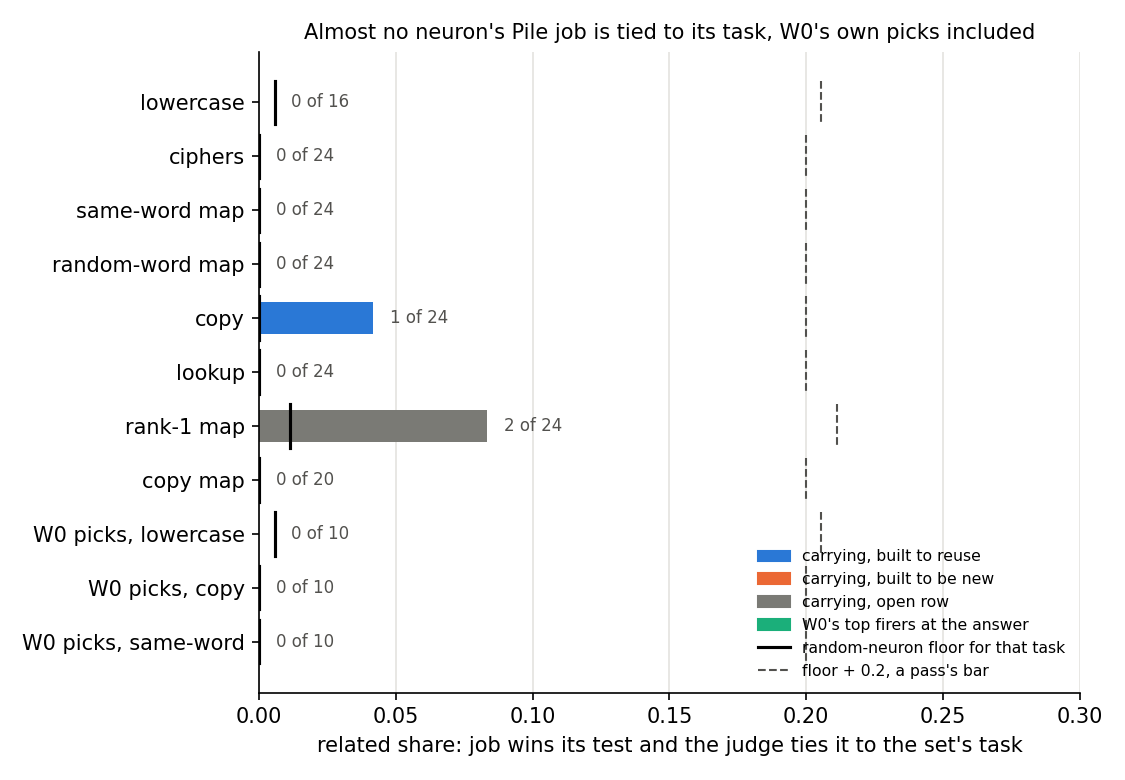

In [2]:
display(Image(FIG / "related_share.png", width=800))


**Reading it.** No, and the control says the method could not have. Lowercase's 16 carrying neurons were tied to
lowercase text zero times; the random floor was one in 179. The W₀ top firers, chosen for firing on the task, were tied
to their task zero times on all three tasks. A pass needed the dashed line, the floor plus 0.2, and no bar reaches half
of it. Three of 150 carrying neurons were tied to their own task, all sensibly: one fires on a digit inside an
identifier that repeats earlier, tied to copying, and two fire on words like " type" before "of", tied to the rank-1
maps' next-word task.

**Why the top firers fail.** The neurons that fire hardest at the answer position are largely the same on every task,
so the thirty top firers are only 22 distinct neurons. Their Pile jobs are about where a text starts, not what it says:

| neuron | picked on | its job, as written |
|---|---|---|
| 5100 | all three tasks | unclear: fires on the first token of a document or snippet (no preceding context) |
| 5424 | all three tasks | Fires on the <\|endoftext\|> token that ends one document and starts the next |
| 726 | copy | The sub-token "all" (or "back", "an") inside a longer word or identifier, e.g. "re\|all\|ocation" |

**Why lowercase's carrying neurons fail.** Most of their jobs are about where a sentence or heading ends:

| neuron | its job, as written |
|---|---|
| 7756 | A sentence-ending period (or ").") right after a citation, page number, or closing factual clause … just before the next sentence begins |
| 10742 | Words inside a title in capitalised title-case (song, album, speech names) |

Those are the positions where lowercase text differs from ordinary text, since the next word is the one whose case the
fine-tune changes. On our own reading after the fact, these neurons serve the task. The judge's brief ruled them out:
"a job that fires … on punctuation … helps none". These two faults, a generic control and a brief that excluded
punctuation, are what Amendment 1 fixed.


### Amendment 1: shown each task's windows, does the judge tie task-specific neurons to their own task?

Each bar is the share of a set that the judge ties to the set's own task, whether or not the job won its test. The black
tick is the same share for random neurons, the floor. Left, the filed judge; right, the amended one, on the same axis.
The task-specific picks were made for the amendment, so the filed judge never saw them as a set.


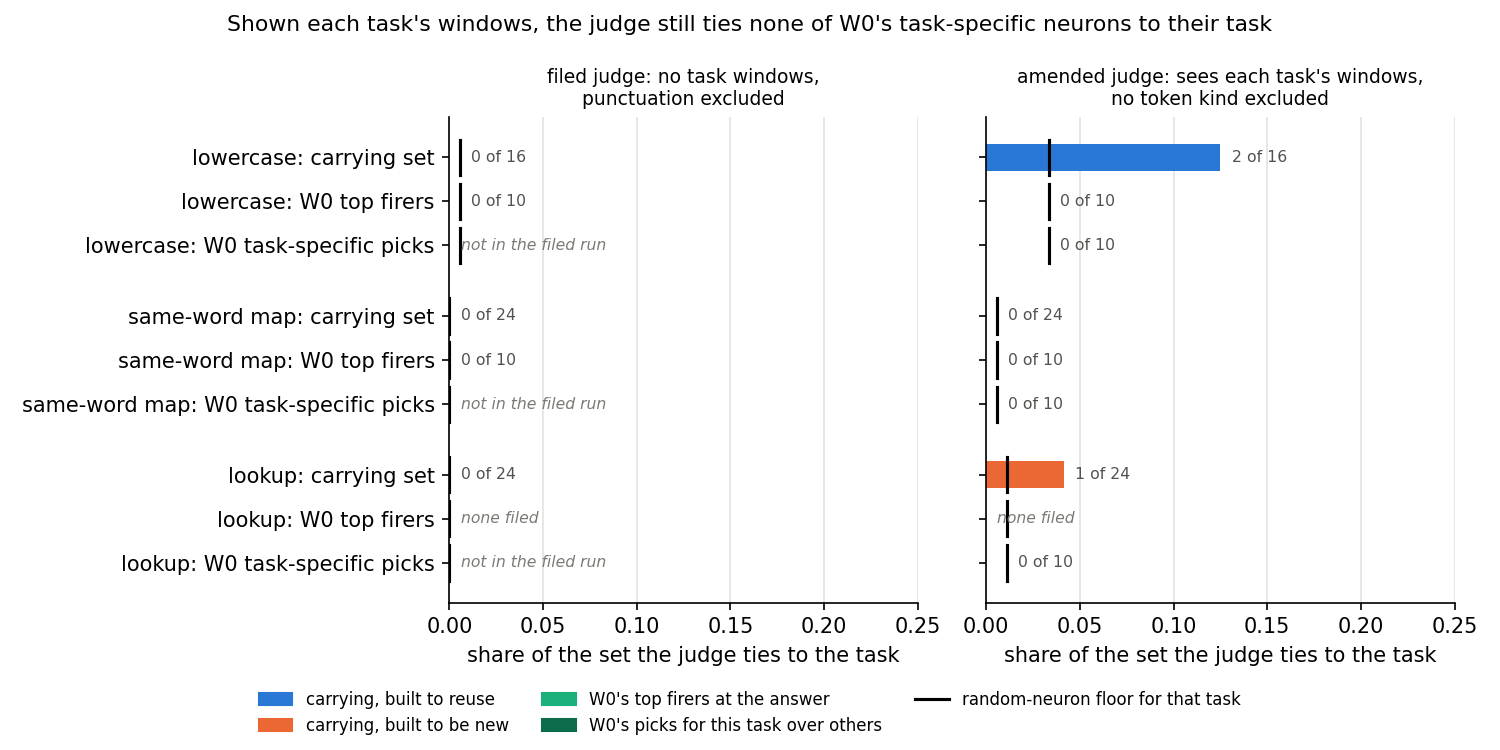

In [3]:
display(Image(FIG / "amend1_controls.png", width=900))


**Reading it.** No, so the route is closed on the 67M, as filed. The amended judge tied none of the thirty
task-specific picks to their own task, against random floors of 0.6% to 3.3%. The top firers stayed at zero too. The
judge did loosen: it tied 21 of 180 random neurons to some task, up from 3. Two of lowercase's 16 carrying neurons, both
sentence-final-period neurons, were now tied to lowercase. That is 0.125 against a floor of 0.028, short of the 0.2 gap a
pass needed, and it is not read because the control failed.

**Why the judge rejects the picks.** The contrast picked neurons that fire on what is unusual about each task's text at
the answer, and their Pile jobs name that formatting in the Pile's own terms:

| task | where the answer is predicted | a pick's job, as written |
|---|---|---|
| lookup | on the marker token ` \+` | Long run of hyphens ("-----") forming a table rule, heading underline or comment divider line |
| lookup | | "#" at the start of a line: C preprocessor directive (#include, #ifndef, #endif) |
| same-word map | on the key word right after ` \+` | Capitalised middle word piece inside a camelCase identifier (summary\|With\|NewElement) |
| same-word map | | The "2" in a fraction "1/2" after "1/" |
| lowercase | at the last word of lowercased text | Middle piece of a proper name or identifier split into tokens (Am\|mon\|ite, p\|53) |

On lookup every pick fires near the top of its Pile range at the marker, and every job names some other rare symbol:
hyphen runs, hashes, slashes, LaTeX signs. On the same-word map the jobs are word pieces glued to a symbol, the shape of
a key right after the marker. Lowercase's picks fire only a little more on it than elsewhere and name fragments of split
names. So the picks are formatting neurons, and the judge is arguably right that none would help produce the answer.
This run cannot tell a judge with no power from task-specific neurons with no nameable task role; either way the
reading has no demonstrated power on this model.


### Are the 67M's neurons as clean as the essay's?


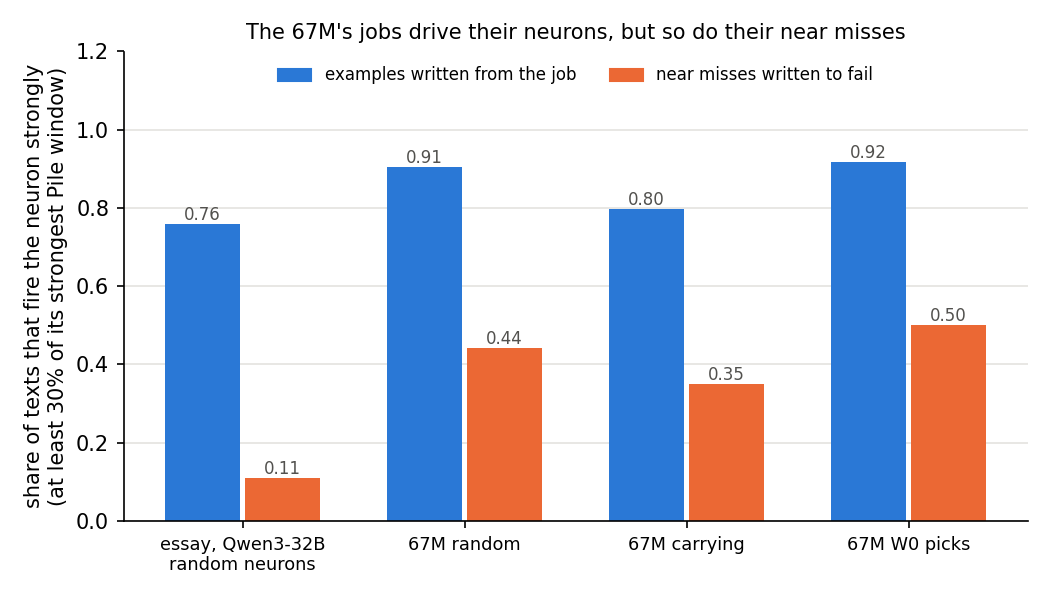

In [4]:
display(Image(FIG / "strong_rates.png", width=750))


**Reading it.** Partly. The jobs drive their neurons: 91% of the examples written for random neurons fired strongly,
against the essay's 76% on Qwen3-32B. But 44% of the near misses fired strongly too, four times the essay's 11%. A
random job still wins its test 82% of the time, against the essay's 90%, because winning only needs more strong
examples than strong near misses. So the 67M's neurons read cleanly as kinds of token, such as identifiers, digits,
sentence ends and word fragments, but a one-line job draws a loose boundary around what fires them.


### Are the rank-1 maps' carrying neurons more coherent than random ones?


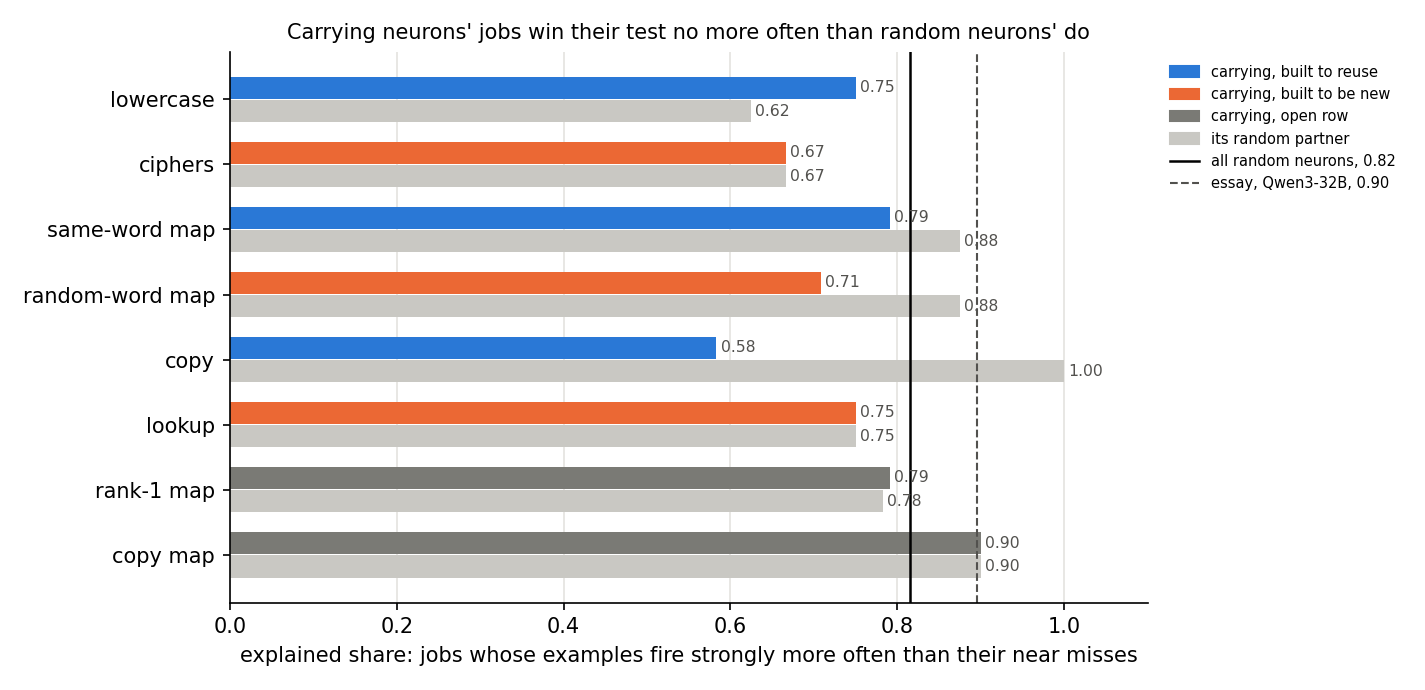

In [5]:
display(Image(FIG / "explained_share.png", width=900))


**Reading it.** No. The rank-1 maps' carrying neurons won their test 79% of the time, against 82% for all random
neurons and 78% for their own random partner. No carrying group beats its partner by much, and the copy group trails
its partner by 0.42. Since the power check failed first, this is reported, not read.

### Before the agents: were lowercase's carrying neurons already firing at the answer?

Barely. Lowercase's carrying set sat about 0.1 above its random sets in the engaged quantile, the ciphers' about 0.04.
The gap of 0.065 is larger than the seeds' spread but under the filed minimum of 0.2, so it reads no separation. Every
apparatus check held: held-out Pile read 0.50, and the neurons picked for firing on each task read 0.98 or more against
random sets near 0.5. The full table is in the report.


## What we learned

The essay's reading works on the 67M as a description: one-line jobs drive their neurons, and most name a kind of
token. It does not work as a reuse reader at this grain. The tasks are synthetic lookups and copies on marker and key
tokens, and a neuron can serve such a task without its Pile job naming it. Amendment 1 removed the brief's exclusion and
the generic control, and the control still read zero. The neurons that fire on one task more than the others are
formatting neurons for its marker, whose Pile jobs describe other symbols. For `GOALS.md`, a neuron being clean does not
by itself give a reuse-versus-new label, so the decomposition's reading gets no rival from this test on the 67M.

## How compelling is the evidence

- **The null belongs to the method.** Both kinds of control read zero on every task under both judges, so a zero or a
  small share on the carrying sets says nothing about reuse.
- **The control may not be a true positive.** The task-specific picks fire on each task's formatting, and the judge may
  be right that they would not help. The failure shows no demonstrated power, not a missed task role.
- **The judges.** The filed judge tied 3 of 180 random neurons to any task and excluded punctuation; the amended one
  tied 21 of 180 and ties the rank-1 maps' description most. One judge call per batch, its noise not measured.
- **One agent of each kind per neuron,** groups of 16 to 24. Tasks covered: lowercase, two ciphers, same-word and
  random-word maps, copy and lookup, the rank-1 and copy maps; task-specific picks on lowercase, the same-word map and
  lookup only.

## Surprises

- The planned positive control read zero. The neurons that fire hardest at the answer are one shared set across tasks.
- The amendment's lean was pass on the same-word map and lookup, and both read zero: their picks are symbol and
  word-fragment neurons for the marker, not neurons about keys or repetition.
- Lowercase's carrying neurons have coherent jobs at sentence and heading ends, where the task acts. Once punctuation was
  allowed, the judge tied two of them to lowercase, still within reach of the floor.
- Near misses fire the 67M's neurons strongly four times as often as in the essay.

## What next

- **Qwen3-1.7B with natural-language tasks,** the filed next step. Jobs and task descriptions share a vocabulary there,
  and a task-specific control can be checked for a nameable role before it is used. If that control rises above the
  floor, run the reuse-against-new comparison; if not, drop the job reading for this question.
- No second amendment on the 67M: the plan closed the route if this control failed.


## Scorecard

| id | claim in words | rule | read | verdict |
|---|---|---|---|---|
| C0 | the firing apparatus works | Pile 0.45-0.55; picks beat random by 0.2; null separates nothing | 0.50; 0.98 vs 0.5; none | pass |
| P0 | lowercase's set more engaged than ciphers' | gap ≥ 0.2 and > spread | 0.065 | fail |
| C1 | judge rarely ties random jobs | share ≤ 0.5 | 3/179 | pass |
| C2 | the win test works on Pile windows | win ≥ 0.8 | 0.92 | pass |
| P1 | lowercase carrying tied to lowercase | floor + 0.2, 2 se | 0/16 vs 1/179 | fail |
| P2 | reuse rows more related | 2 of 3 rows | 0 of 3 | fail, not read |
| P3 | rank-1 set coherent | base + 0.2, 2 se | 0.79 vs 0.82 | not coherent, not read |
| R | W₀ top firers above floor | lean above | 0/10 on each task | below or level |
| A1 C1a | amended judge ties task-specific picks to their task | floor + 0.2, 2 se, every task | 0/10 each; floors 0.6-3.3% | fail: route closed on 67M |
| A1 C1b | picks tied to own task over other control tasks | same rule | 0 vs 0.1, 0, 0 | fail |
| A1 C1_fp | amended judge rarely ties random jobs | share ≤ 0.5 | 21/180 | pass |
| A1 P1 | as P1, amended judge | as P1 | 2/16 vs 5/179 | not read |
| A1 P2 | as P2, amended judge | as P2 | 0 of 3 | not read |

## Departures from the literature

From the essay's "Explanations That Could Lose" protocol, https://already-clean.goodfire.com/essay.md:

- The 67M and 2,000 Pile rows instead of Qwen3-32B and its corpus.
- A writer that sees 20 windows, with no tools, instead of an investigating agent.
- A stated win rule, more strong examples than strong near misses; the essay reports wins without stating its rule.
- Carrying and W₀-picked neurons beside random ones; the essay reads random neurons only.
- The judge, its task windows and the engaged quantile are ours, not the essay's.
- The essay's distant-concept control was not run.

## Not run

- The essay's distant-concept control; a second agent of any kind per neuron.
- A check that the task-specific picks have a task role at all, such as ablating them, before using them as a control.
- Task-specific picks for the other tasks; the maximiser on the 24 new picks.
- Elicit and the rank-1 maps' cipher in the agent stage; steering or ablating the carrying neurons.
- One random neuron of 352 is unscored: its maximiser wrote all ten texts as examples and no near misses.
- A second amendment on the 67M, closed by the filed rule. The filed next step: Qwen3-1.7B with natural-language tasks.

## Provenance

Stage 0: `experiments/carrying_jobs/results/stage0.json`, MATS `debug` job 52876, L40, about a minute, $0. An earlier
job, 52866, died on a missing results link. Agents: 36 Sonnet calls, `results/stage1/`. Maximiser scoring: job 52885,
`results/stage1/max_scores.json`. Score: `score.py score` → `results/score.json`. Amendment 1: controls job 52944,
`debug`, L40, under a minute, $0; one writer and 12 judge calls, `results/stage1/{writer/c00,judge_amend1}`; score
`score.py amend1-score` → `results/score_amend1.json`. Figures: `plot.py`.
